In [26]:
import pandas as pd

# Load the Oregon Workers' Compensation dataset
file_path = "/content/export.csv"
df = pd.read_csv(file_path, low_memory=False)

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Display first five records
display(df.head())

# Examine column names and data types
df.info()

# Display all column names
print("\nAll Dataset Columns:")
for col in df.columns:
 print(col)

Dataset shape: (220302, 31)


,Claim Number,Claim Reference Year,Date of Injury,County of Injury,Age Range,Gender,Occupation Code,Occupation Description,Tenure,Nature of Injury Code,...,NAICS Code (Description),Employer Number,Employer Location Number,Number of employees,Employer Name,Employer Address 1,Employer Address 2,Employer City,Employer State,Employer Zip Code
0,Claim182709,2023,2022Q4,Malheur,45-54,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",2nd-3rd years,1232,...,OILSEED AND GRAIN FARMING,EmpX4442695,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted
1,Claim152988,2021,2021Q4,Sherman,35-44,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",26th and more,111,...,OILSEED AND GRAIN FARMING,EmpX5675530,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted
2,Claim210095,2024,2024Q1,Morrow,25-34,M,452093,"Farmworkers, Farm and Ranch Animals",4th-5th years,132,...,CORN FARMING,8871014,3,50-99,FREDERICKSON FARMING LLC,NaN,80702 PATERSON FERRY RD,IRRIGON,OR,97844
3,Claim165730,2022,2021Q4,Morrow,Over 65,M,493031,Bus and Truck Mechanics and Diesel Engine Spec...,6th-10th years,1839,...,CORN FARMING,8871014,3,50-99,FREDERICKSON FARMING LLC,NaN,80702 PATERSON FERRY RD,IRRIGON,OR,97844
4,Claim36268,2016,2016Q3,Umatilla,25-34,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",First month,185,...,OILSEED AND GRAIN FARMING,EmpX840139,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220302 entries, 0 to 220301
Data columns (total 31 columns):
 #   Column                                    Non-Null Count   Dtype 
---  ------                                    --------------   ----- 
 0   Claim Number                              220302 non-null  object
 1   Claim Reference Year                      220302 non-null  int64 
 2   Date of Injury                            220302 non-null  object
 3   County of Injury                          220302 non-null  object
 4   Age Range                                 220302 non-null  object
 5   Gender                                    220272 non-null  object
 6   Occupation Code                           220302 non-null  int64 
 7   Occupation Description                    220196 non-null  object
 8   Tenure                                    220302 non-null  object
 9   Nature of Injury Code                     220302 non-null  int64 
 10  Nature of Injury (Description)  

### Check Missing Values and Duplicate Records

Identifying missing values and duplicate records to assess the dataset's quality before cleaning. We'll calculate missing percentages.

In [27]:
# Check missing values for each column
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

# Display columns with missing values, highest first
display(
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values(by='Missing_Percentage', ascending=False)
)

# Check for completely duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

,Missing_Count,Missing_Percentage
Employer Address 1,154046,69.92
Employer State,3690,1.67
NAICS Code (Description),1036,0.47
Employer City,1010,0.46
Occupation Description,106,0.05
Gender,30,0.01
Nature of Injury (Description),32,0.01
Employer Address 2,12,0.01
Employer Zip Code,9,0.00


Duplicate records: 0
Duplicate percentage: 0.0 %


The dataset contains 0 duplicate records (0.0%). No duplicate removal is required.

### Examine Numerical and Categorical Variables

Identifying numerical and categorical columns and reviewing their summary statistics. This helps us understand the distribution of values and identify potential data-quality issues.

In [28]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Display the number of columns in each group
print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

# Review numerical statistics, including min, max, and quartiles
display(df[numerical_cols].describe().T)

# Review categorical statistics, including unique values and frequency
display(df[categorical_cols].describe().T)

Numerical columns: 8
Categorical columns: 23


,count,mean,std,min,25%,50%,75%,max
Claim Reference Year,220302.0,2019.652250,2.829334,2015.0,2017.0,2020.0,2022.0,2024.0
Occupation Code,220302.0,445687.379034,167577.135913,870.0,352014.0,452093.0,519199.0,999999.0
Nature of Injury Code,220302.0,1034.065782,848.882817,0.0,143.0,1232.0,1232.0,9999.0
Body Part Injured Code,220302.0,774.819716,1369.942297,6.0,52.0,322.0,512.0,9999.0
Event of Injury Code,220302.0,4327.174324,2863.595603,20.0,722.0,4333.0,7111.0,9999.0
Source of Injury Code,220302.0,3532.707384,3141.764258,10.0,562.0,2131.0,6620.0,9999.0
Secondary Source of Injury Code,220302.0,8777.931635,2807.870291,10.0,9999.0,9999.0,9999.0,9999.0
NAICS Code,220302.0,436968.127970,248764.215310,1111.0,311412.0,481111.0,622110.0,999999.0


,count,unique,top,freq
Claim Number,220302,220302,Claim182709,1
Date of Injury,220302,149,2021Q3,6915
County of Injury,220302,38,Multnomah,50143
Age Range,220302,7,25-34,50538
Gender,220272,2,M,136656
Occupation Description,220196,770,"Laborers and Freight, Stock, and Material Move...",14778
Tenure,220302,10,Not available,41904
Nature of Injury (Description),220270,317,"Sprains, strains",90836
Body Part Injured (Description),220302,153,Lumbar region,28134
Event of Injury (Description),220302,383,"Overexertion in lifting, lowering-single episode",19214


- 220,302 records and 31 variables: 8 numerical and 23 categorical.
- Claim Number: All 220,302 values are unique, supporting one record per claim.
- Date of Injury: Contains quarterly values such as 2021Q3, rather than exact dates.
- Injury codes: Although stored as numerical values, these represent categories and should not be treated as continuous measurements.
- Missing values: Employer Address 1 has substantial missing data (approximately 69.9%). Other variables have smaller amounts of missing data.
- Special values: Codes such as 9999, 999999, and labels such as Not available, Nonclassifiable, and Redacted require investigation before cleaning.
Important observation: None of the 31 variables clearly represents claim severity or duration. We need to investigate this before selecting a prediction target.

## Examine Injury and Claim Characteristics

Examining the distribution of important categorical variables to understand common injuries, worker characteristics and industry patterns.

In [29]:
# Select important variables for initial EDA
eda_columns = [
    'Age Range',
    'Gender',
    'Tenure',
    'Nature of Injury (Description)',
    'Body Part Injured (Description)',
    'Ownership',
    'Number of employees'
]

# Display the 10 most frequent categories for each variable
for col in eda_columns:
    print(f"\n{col}")

    # Calculate category frequencies and percentages
    summary = pd.DataFrame({
        'Count': df[col].value_counts(dropna=False),
        'Percentage': (
            df[col].value_counts(normalize=True, dropna=False) * 100
        ).round(2)
    })

    display(summary.head(10))


Age Range


,Count,Percentage
Age Range,,
25-34,50538,22.94
45-54,47066,21.36
35-44,46706,21.20
55-64,37864,17.19
18-24,27634,12.54
Over 65,9063,4.11
Under 18,1431,0.65



Gender


,Count,Percentage
Gender,,
M,136656,62.03
F,83616,37.96
NaN,30,0.01



Tenure


,Count,Percentage
Tenure,,
Not available,41904,19.02
2nd-3rd years,37936,17.22
11th-25th years,24561,11.15
6th-10th years,21080,9.57
7th-12th months,20476,9.29
First month,19448,8.83
4th-5th years,17595,7.99
4th-6th months,16152,7.33
2nd-3rd months,15881,7.21


... (4 outputs left out)


Ownership


,Count,Percentage
Ownership,,
Private ownership,192728,87.48
Local government,20532,9.32
State government,7041,3.20
Unknown,1,0.00



Number of employees


,Count,Percentage
Number of employees,,
500 or more,73968,33.58
100-499,47016,21.34
11-49,41023,18.62
1-10,31358,14.23
50-99,26895,12.21
unavailable,42,0.02


EDA Key finding  

Age Range	Ages 25–34 represent the largest group (22.94%).

Gender	Male workers account for 62.03% of claims.

Tenure	19.02% have unavailable tenure information.

Nature of Injury	Sprains and strains account for 41.23% of claims.

Body Part Injured	Lumbar region is the most common (12.77%).

Ownership	Private employers account for 87.48% of claims.

Number of Employees	Employers with 500+ employees account for 33.58% of claims.

Important: These findings describe the distribution of accepted disabling claims, not which groups have higher injury rates or more severe outcomes.

## Visualize Important Claim Characteristics

Creating clear visualizations of the most common injury types, injured body parts and worker age groups. These will help us identify patterns and provide figures for capstone report.

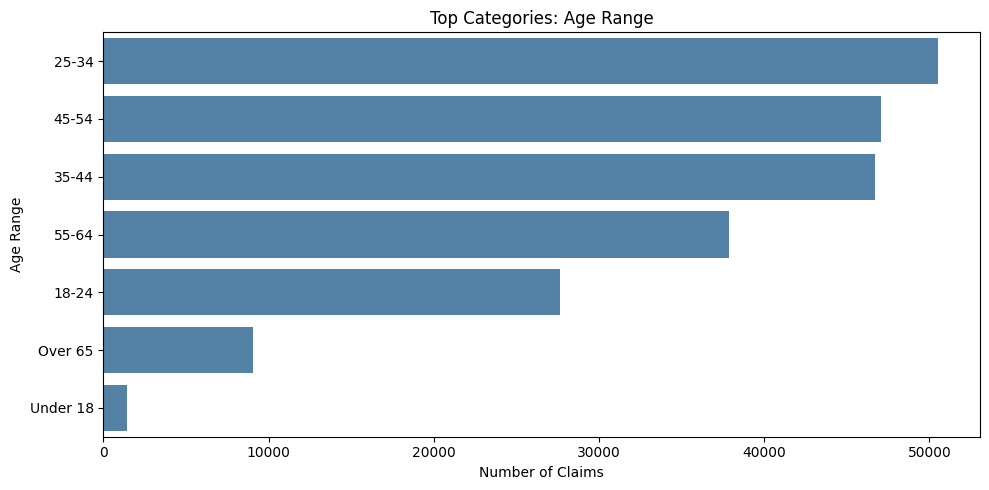

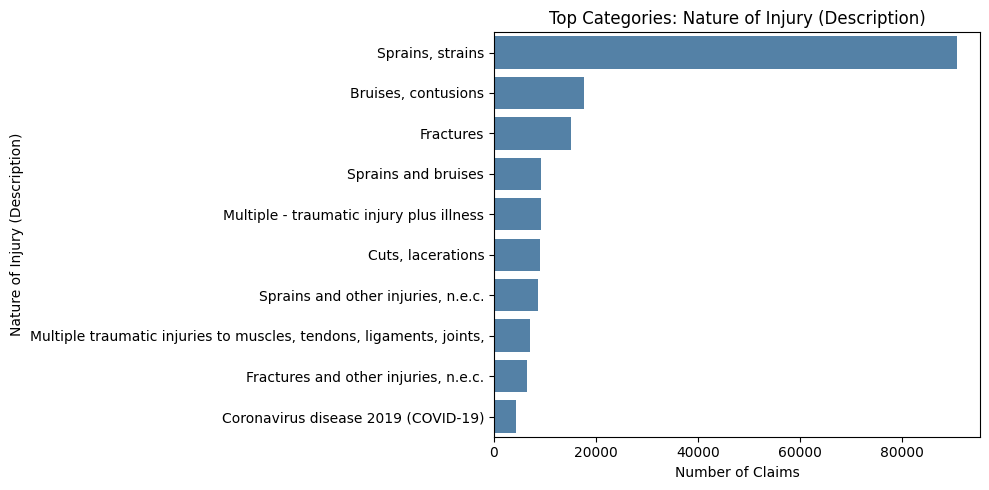

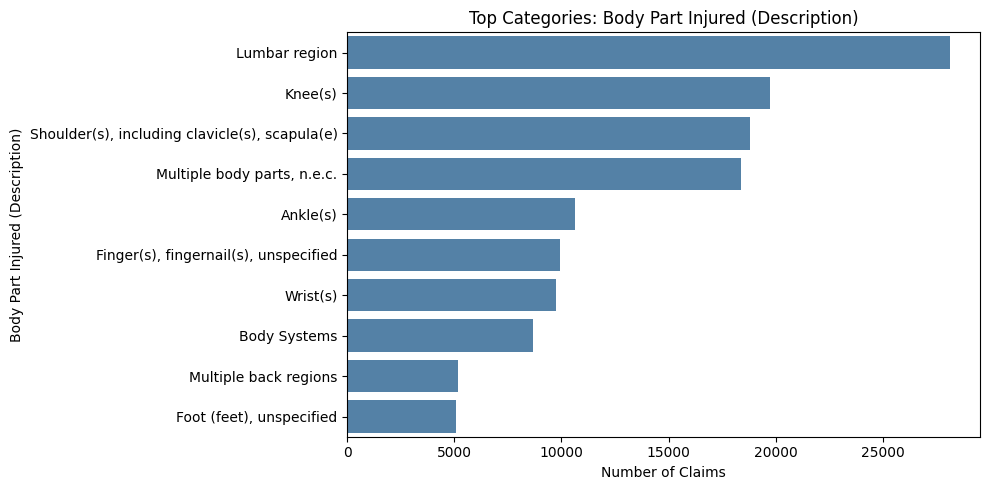

In [30]:
 import matplotlib.pyplot as plt
import seaborn as sns

# Select variables for visualization
plot_columns = [
    'Age Range',
    'Nature of Injury (Description)',
    'Body Part Injured (Description)'
]

# Create a separate chart for each variable
for col in plot_columns:

    # Select the 10 most common categories
    counts = df[col].value_counts().head(10)

    plt.figure(figsize=(10, 5))

    # Create horizontal bar chart
    sns.barplot(
        x=counts.values,
        y=counts.index,
        color='steelblue'
    )

    # Add descriptive titles and axis labels
    plt.title(f'Top Categories: {col}')
    plt.xlabel('Number of Claims')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

## EDA Visualization Findings

Age Range	Workers aged 25–34 account for the largest proportion of claims (22.94%).

Nature of Injury	Sprains and strains dominate, accounting for 41.23% of claims.

Body Part Injured	The lumbar region is the most frequently injured body part (12.77%).



## Analyze Yearly Claim Trends

Examining how the number of claims changes between 2015 and 2024. This helps identify historical trends and unusual fluctuations.

,count
Claim Reference Year,
2015,19550
2016,20447
2017,20978
2018,20996
2019,22399
2020,21859
2021,24384
2022,24947
2023,22993


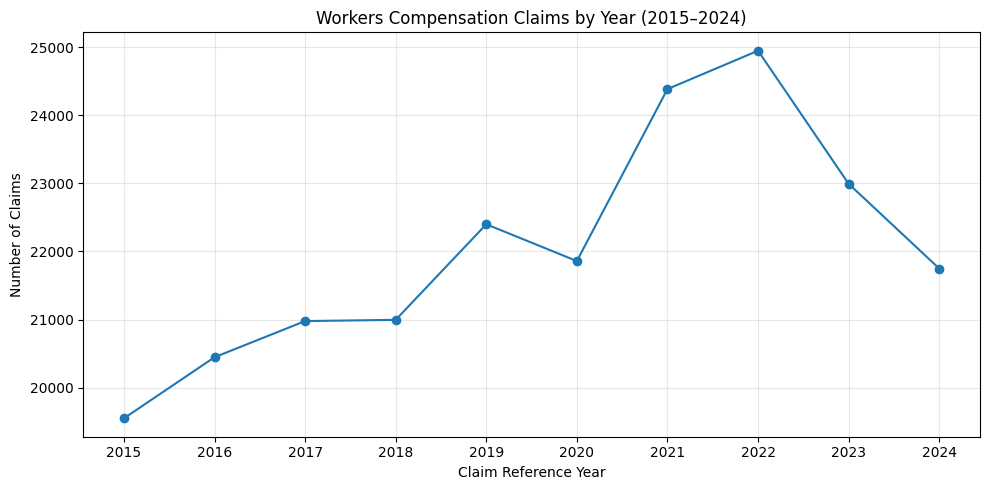

In [31]:
# Count claims for each reference year
yearly_claims = (
    df['Claim Reference Year']
    .value_counts()
    .sort_index()
)

# Display yearly claim counts
display(yearly_claims)

# Visualize yearly claim trends
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_claims.index,
    yearly_claims.values,
    marker='o'
)

# Add chart title and labels
plt.title('Workers Compensation Claims by Year (2015–2024)')
plt.xlabel('Claim Reference Year')
plt.ylabel('Number of Claims')
plt.xticks(yearly_claims.index)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- 2015–2019: Claims generally increased, from approximately 19,500 to 22,400.
- 2020: A slight decline occurred.
- 2021–2022: Claims increased significantly, reaching their highest level in 2022 at approximately 24,900.
- 2023–2024: Claims declined, reaching approximately 21,700 in 2024.
These fluctuations may reflect changes in workplace conditions, reporting patterns or other factors but we cannot determine their causes from this chart alone.

## Examine Missing Values and Special Codes

In [32]:
# Calculate missing values for every column
missing = df.isna().sum()

# Calculate percentage of missing values
missing_pct = (missing / len(df) * 100).round(2)

# Create a summary table
missing_table = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

# Display columns with missing values
display(
    missing_table[missing_table['Missing Count'] > 0]
    .sort_values('Missing %', ascending=False)
)

,Missing Count,Missing %
Employer Address 1,154046,69.92
Employer State,3690,1.67
NAICS Code (Description),1036,0.47
Employer City,1010,0.46
Occupation Description,106,0.05
Gender,30,0.01
Nature of Injury (Description),32,0.01
Employer Address 2,12,0.01
Employer Zip Code,9,0.00


frequency of placeholder values in the injury classification codes.

In [33]:
# Identify injury classification code columns
code_cols = [
    'Nature of Injury Code',
    'Body Part Injured Code',
    'Event of Injury Code',
    'Source of Injury Code',
    'Secondary Source of Injury Code'
]

# Count placeholder code 9999 in each column
for col in code_cols:
    count = (df[col] == 9999).sum()
    percentage = count / len(df) * 100

    print(f"{col}: {count:,} ({percentage:.2f}%)")

Nature of Injury Code: 171 (0.08%)
Body Part Injured Code: 179 (0.08%)
Event of Injury Code: 5,372 (2.44%)
Source of Injury Code: 9,336 (4.24%)
Secondary Source of Injury Code: 173,083 (78.57%)


## Investigate Placeholder Codes

Checking the descriptions associated with 9999 to understand whether it represents missing information an unknown category or a valid classification.

In [34]:
# Match each injury code with its description
code_pairs = {
    'Nature of Injury Code': 'Nature of Injury (Description)',
    'Body Part Injured Code': 'Body Part Injured (Description)',
    'Event of Injury Code': 'Event of Injury (Description)',
    'Source of Injury Code': 'Source of Injury (Description)',
    'Secondary Source of Injury Code':
        'Secondary Source of Injury (Description)'
}

# Examine descriptions associated with code 9999
for code_col, desc_col in code_pairs.items():

    print(f"\n{code_col}")

    # Show descriptions and their frequencies
    results = df.loc[
        df[code_col] == 9999, desc_col
    ].value_counts(dropna=False)

    display(results.head(10))


Nature of Injury Code


,count
Nature of Injury (Description),
Nonclassifiable,171



Body Part Injured Code


,count
Body Part Injured (Description),
Nonclassifiable,179



Event of Injury Code


,count
Event of Injury (Description),
Nonclassifiable,5372



Source of Injury Code


,count
Source of Injury (Description),
Nonclassifiable,9336



Secondary Source of Injury Code


,count
Secondary Source of Injury (Description),
Nonclassifiable,173083


Placeholder Codes

Results confirm that code 9999 corresponds to "Nonclassifiable" across all five injury classification variables.

The most significant finding is that 78.57% of records have a nonclassifiable secondary injury source.

We should retain these values during EDA rather than automatically deleting records. However, we may consider excluding the secondary source variable during modeling because it contains limited classification information.

## Examine Injury Patterns Across Years

Examining how common injury types change between 2015 and 2024. This helps us understand whether injury patterns remain consistent over time.

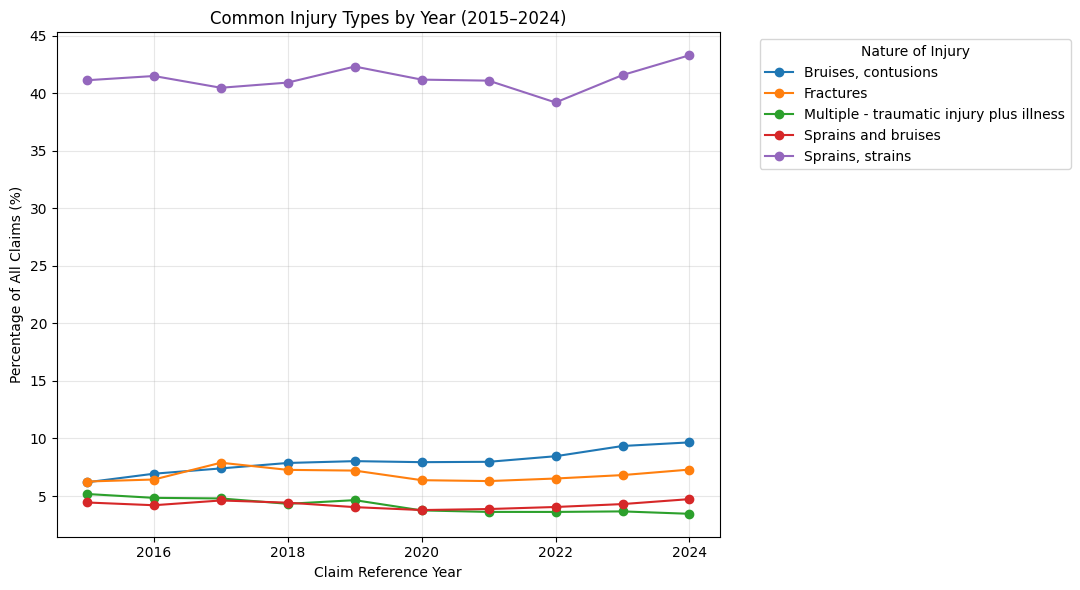

In [35]:
# Select the five most common injury types
top_injuries = (
    df['Nature of Injury (Description)']
    .value_counts()
    .head(5)
    .index
)

# Filter records to these injury types
injury_data = df[
    df['Nature of Injury (Description)'].isin(top_injuries)
]

# Count claims by year and injury type
injury_trends = pd.crosstab(
    injury_data['Claim Reference Year'],
    injury_data['Nature of Injury (Description)']
)

# Calculate each injury type's share of all claims per year
injury_pct = injury_trends.div(
    df.groupby('Claim Reference Year').size(),
    axis=0
) * 100

# Plot yearly injury patterns
ax = injury_pct.plot(figsize=(11, 6), marker='o')

plt.title('Common Injury Types by Year (2015–2024)')
plt.xlabel('Claim Reference Year')
plt.ylabel('Percentage of All Claims (%)')
plt.legend(title='Nature of Injury', bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Target Variable and Feature Engineering



In [36]:
# Display all 31 column names
for col in df.columns:
    print(col)

Claim Number
Claim Reference Year
Date of Injury
County of Injury
Age Range
Gender
Occupation Code
Occupation Description
Tenure
Nature of Injury Code
Nature of Injury (Description)
Body Part Injured Code
Body Part Injured (Description)
Event of Injury Code
Event of Injury (Description)
Source of Injury Code
Source of Injury (Description)
Secondary Source of Injury Code
Secondary Source of Injury (Description)
Ownership
NAICS Code
NAICS Code (Description)
Employer Number
Employer Location Number
Number of employees
Employer Name
Employer Address 1
Employer Address 2
Employer City
Employer State
Employer Zip Code


In [37]:
# Explore potential target variables

print("Nature of Injury categories:")
print(
    df["Nature of Injury (Description)"]
    .value_counts()
    .head(20)
)

print("\nBody Part Injured categories:")
print(
    df["Body Part Injured (Description)"]
    .value_counts()
    .head(20)
)

print("\nMissing values:")
print(
    df[
        [
            "Nature of Injury (Description)",
            "Body Part Injured (Description)"
        ]
    ].isnull().sum()
)


Nature of Injury categories:
Nature of Injury (Description)
Sprains, strains                                                       90836
Bruises, contusions                                                    17674
Fractures                                                              15050
Sprains and bruises                                                     9327
Multiple - traumatic injury plus illness                                9156
Cuts, lacerations                                                       9106
Sprains and other injuries, n.e.c.                                      8648
Multiple traumatic injuries to muscles, tendons, ligaments, joints,     7060
Fractures and other injuries, n.e.c.                                    6422
Coronavirus disease 2019 (COVID-19)                                     4269
Multiple - sprains/strains and tears                                    3966
Exposures to disease or harmful substance - no illness incurred         3013
Hernias, any typ

In [38]:
# Data Quality Analysis

# Check missing values across all columns
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_pct.round(2)
})

print("Missing Values Summary:")
display(missing_summary.sort_values(
    by="Missing Values", ascending=False
))

# Check duplicate claim identifiers
print("\nDuplicate Claim Numbers:")
print(df["Claim Number"].duplicated().sum())

# Check overall dataset size
print("\nTotal Claims:", len(df))


Missing Values Summary:


,Missing Values,Missing Percentage
Employer Address 1,154046,69.92
Employer State,3690,1.67
NAICS Code (Description),1036,0.47
Employer City,1010,0.46
Occupation Description,106,0.05
Nature of Injury (Description),32,0.01
Gender,30,0.01
Employer Address 2,12,0.01
Employer Zip Code,9,0.00
Occupation Code,0,0.00



Duplicate Claim Numbers:
0

Total Claims: 220302


# Feature Engineering and Data Preparation
The Date of Injury field contains quarterly periods (for example, 2022Q4), not exact calendar dates. We derive injury year and quarter, industry sector, and indicators for fractures and multiple injured body parts. These features describe injury characteristics; they do not measure claim costs or financial severity.

In [39]:
import pandas as pd
import numpy as np

# Work on a copy so the original EDA data remains unchanged
df_model = df.copy()

# Dates are reported as quarters, not exact dates
injury_periods = pd.PeriodIndex(df_model["Date of Injury"].astype(str), freq="Q")
df_model["Injury_Year"] = injury_periods.year
df_model["Injury_Quarter"] = injury_periods.quarter

df_model["Industry_Sector"] = (
    df_model["NAICS Code"].astype("string")
    .str.extract(r"^(\\d{2})", expand=False)
)
df_model["Multiple_Body_Parts"] = (
    df_model["Body Part Injured (Description)"].astype("string")
    .str.contains("multiple", case=False, na=False).astype(int)
)
df_model["Fracture_Indicator"] = (
    df_model["Nature of Injury (Description)"].astype("string")
    .str.contains("fracture", case=False, na=False).astype(int)
)
new_features = [
    "Injury_Year", "Injury_Quarter", "Industry_Sector",
    "Multiple_Body_Parts", "Fracture_Indicator"
]
print("Feature Engineering Complete!")
display(df_model[new_features].head())
print("Total claims:", len(df_model))
print("Total columns:", df_model.shape[1])


/tmp/ipykernel_933/1443365224.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_model["Date of Injury"] = pd.to_datetime(


Feature Engineering Complete!


,Injury_Year,Injury_Month,Industry_Sector,Multiple_Body_Parts,Fracture_Indicator
0,2022,10,11,0,0
1,2021,10,11,0,1
2,2024,1,11,0,0
3,2021,10,11,0,1
4,2016,7,11,0,0



Total claims: 220302
Total columns: 36


# Feature Engineering Validation
After creating the new features, we will review their distributions and missing values to confirm that the transformations were completed correctly. This step helps identify potential data quality issues before proceeding with machine learning.

In [40]:
# Review newly engineered features
print("New Feature Summary:")
display(df_model[new_features].describe(include="all"))

# Check missing values
print("\nMissing Values:")
print(df_model[new_features].isnull().sum())

# Check fracture distribution
print("\nFracture Indicator:")
print(df_model["Fracture_Indicator"].value_counts())

# Check multiple body part injuries
print("\nMultiple Body Parts:")
print(df_model["Multiple_Body_Parts"].value_counts())

# Confirm claim count has not changed
print("\nOriginal claims:", len(df))
print("Claims after feature engineering:", len(df_model))


New Feature Summary:


,Injury_Year,Injury_Month,Industry_Sector,Multiple_Body_Parts,Fracture_Indicator
count,220302.000000,220302.000000,220302,220302.000000,220302.000000
unique,NaN,NaN,25,NaN,NaN
top,NaN,NaN,62,NaN,NaN
freq,NaN,NaN,35796,NaN,NaN
mean,2019.398244,5.527930,NaN,0.139186,0.100231
std,2.975007,3.334595,NaN,0.346142,0.300308
min,1967.000000,1.000000,NaN,0.000000,0.000000
25%,2017.000000,4.000000,NaN,0.000000,0.000000
50%,2020.000000,7.000000,NaN,0.000000,0.000000
75%,2022.000000,7.000000,NaN,0.000000,0.000000



Missing Values:
Injury_Year            0
Injury_Month           0
Industry_Sector        0
Multiple_Body_Parts    0
Fracture_Indicator     0
dtype: int64

Fracture Indicator:
Fracture_Indicator
0    198221
1     22081
Name: count, dtype: int64

Multiple Body Parts:
Multiple_Body_Parts
0    189639
1     30663
Name: count, dtype: int64

Original claims: 220302
Claims after feature engineering: 220302


Feature engineering created injury year and quarter from the reported quarterly injury period, a two-digit industry sector from NAICS, and indicators for fractures and multiple injured body parts. No exact injury month is available in the source data. The resulting indicators are descriptive and are not independently validated measures of financial severity.

In [41]:
# Validate injury dates and claim reference years

print("Injury Date Validation")

print("\nOriginal date examples:")
print(df["Date of Injury"].head(10))

print("\nInjury year distribution:")
print(df_model["Injury_Year"].value_counts().sort_index())

print("\nClaim reference year distribution:")
print(df["Claim Reference Year"].value_counts().sort_index())

print("\nClaims with injury years before 2015:")
print((df_model["Injury_Year"] < 2015).sum())

print("\nMissing injury years:")
print(df_model["Injury_Year"].isna().sum())

Injury Date Validation

Original date examples:
0    2022Q4
1    2021Q4
2    2024Q1
3    2021Q4
4    2016Q3
5    2016Q3
6    2023Q3
7    2015Q1
8    2018Q3
9    2024Q2
Name: Date of Injury, dtype: object

Injury year distribution:
Injury_Year
1967        1
1969        1
1970        2
1971        1
1973        1
1976        2
1978        1
1979        2
1981        1
1984        1
1985        2
1986        5
1987        3
1988        2
1989        2
1990        2
1991        2
1992        1
1993        4
1994        1
1995        4
1996        4
1997       11
1998       17
1999       12
2000       15
2001       12
2002       17
2003       14
2004       13
2005       31
2006       23
2007       26
2008       62
2009       37
2010       34
2011       80
2012      113
2013      415
2014     4137
2015    19436
2016    20679
2017    21006
2018    21224
2019    22108
2020    21882
2021    24394
2022    24782
2023    22110
2024    17567
Name: count, dtype: int64

Claim reference year distribut

# Injury Date Parsing and Validation

In [42]:
# Confirm quarter-based features and report the historical injury dates
print("Injury Date Validation Complete")
display(df_model[["Injury_Year", "Injury_Quarter"]].head(10))
print("\nMissing injury years:", df_model["Injury_Year"].isna().sum())
print("Claims before 2015:", (df_model["Injury_Year"] < 2015).sum())
print("Total claims:", len(df_model))


Injury Date Validation Complete


,Injury_Year,Injury_Quarter
0,2022,4
1,2021,4
2,2024,1
3,2021,4
4,2016,3
5,2016,3
6,2023,3
7,2015,1
8,2018,3
9,2024,2



Missing injury years:
0

Claims before 2015:
5114

Total claims:
220302


The injury date validation confirmed that the quarterly injury dates were successfully converted into separate year and quarter variables. The dataset still contains 220,302 claims, with no missing injury years. We also identified 5,114 claims with injury dates before 2015, even though the claim reference years range from 2015 to 2024. These older injuries may represent claims that continued into later reporting periods. For now, these records will be retained until we determine whether they should be included in the predictive modeling process.

##Target Variable Identification

In [43]:
# Review all available dataset columns
print("Available Dataset Columns:")
for col in df_model.columns:
    print(col)

# Search for possible claim severity targets
keywords = [
    "cost", "paid", "reserve", "incurred",
    "amount", "severity", "benefit",
    "indemnity", "medical"
]

target_columns = [
    col for col in df_model.columns
    if any(word in col.lower() for word in keywords)
]

print("\nPotential Severity Target Columns:")
print(target_columns)

Available Dataset Columns:
Claim Number
Claim Reference Year
Date of Injury
County of Injury
Age Range
Gender
Occupation Code
Occupation Description
Tenure
Nature of Injury Code
Nature of Injury (Description)
Body Part Injured Code
Body Part Injured (Description)
Event of Injury Code
Event of Injury (Description)
Source of Injury Code
Source of Injury (Description)
Secondary Source of Injury Code
Secondary Source of Injury (Description)
Ownership
NAICS Code
NAICS Code (Description)
Employer Number
Employer Location Number
Number of employees
Employer Name
Employer Address 1
Employer Address 2
Employer City
Employer State
Employer Zip Code
Injury_Year
Injury_Month
Industry_Sector
Multiple_Body_Parts
Fracture_Indicator
Injury_Quarter

Potential Severity Target Columns:
[]


## Injury Risk Distribution

In [44]:
import numpy as np

# Create exploratory risk score
df_model["Risk_Score"] = (
    df_model["Fracture_Indicator"].astype(int)
    + df_model["Multiple_Body_Parts"].astype(int)
)

# Create risk categories
df_model["Risk_Category"] = np.select(
    [
        df_model["Risk_Score"] == 0,
        df_model["Risk_Score"] == 1,
        df_model["Risk_Score"] == 2
    ],
    ["Low", "Moderate", "High"],
    default="Unknown"
)

print("Risk Classification Complete!")
print(df_model["Risk_Category"].value_counts())


Risk Classification Complete!
Risk_Category
Low         170120
Moderate     47620
High          2562
Name: count, dtype: int64


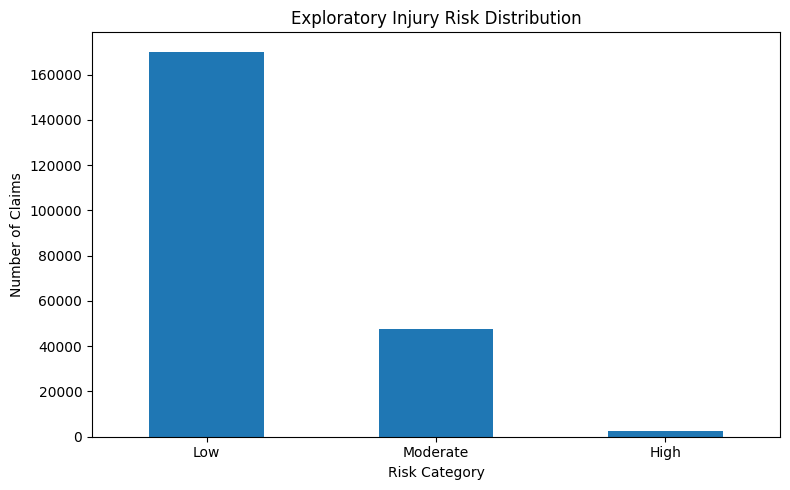

In [45]:
import matplotlib.pyplot as plt

risk_counts = (
    df_model["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"], fill_value=0)
)

plt.figure(figsize=(8, 5))
risk_counts.plot(kind="bar")

plt.title("Exploratory Injury Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Claims")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The graph shows that most workers’ compensation claims fall into the low risk category based on our exploratory classification. A smaller number of claims fall into the moderate risk category, while high risk claims represent the smallest group. These results suggest that fractures and injuries involving multiple body parts are less common in the dataset. However, these classifications are based on selected injury characteristics rather than actual claim costs or medical outcomes. Additional data would be needed to determine whether these categories accurately reflect claim severity.

The exploratory analysis identified an important limitation in the Oregon workers’ compensation dataset. Although the dataset contains information about injury characteristics, occupations, industries, and employers, it does not include a direct measure of claim severity, such as total incurred costs, paid benefits, or claim duration.

To continue the analysis, we developed an exploratory injury risk classification using two engineered features: Fracture_Indicator and Multiple_Body_Parts. Claims were categorized as Low, Moderate, or High based on the presence of these characteristics.

The analysis classified 170,120 claims as Low risk, 47,620 as Moderate risk, and 2,562 as High risk. Most claims fell into the Low risk category.

These categories represent injury characteristics rather than actual financial claim severity. Future modeling will require an appropriate outcome variable or additional claims cost data to support the project’s original financial severity prediction objective.

**Modeling caution:** Because Risk_Category is calculated directly from Fracture_Indicator and Multiple_Body_Parts, using either of those indicators to predict Risk_Category would create target leakage. The exploratory risk labels should not be presented as independently observed claim severity outcomes.

## Reproducibility and publication checks
Before sharing on GitHub, rerun all cells after uploading the source CSV in Colab. Do not commit raw employer names, addresses, claim identifiers, or other potentially identifying records. Review saved cell outputs for individual records, and publish only approved aggregate summaries. The risk categories are exploratory proxies, not observed financial severity.